# Actividad 8 Individual – Regresión no lineal
**Variable respuesta (y):** `SALIDAS` · **Variables predictoras (x):** `SKU` y `NOMBRE` (convertidas a numérico)
**Modelos comparados por cada predictora:** (1) Lineal simple, (2) Exponencial, (3) Potencial
Fuente: hoja `Histórico_Entradas_SAlidas` de `Datos_Complementarios_CLV.xlsx`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import curve_fit
pd.set_option('display.width',200); pd.set_option('display.max_columns',30)
raw = pd.read_excel('Datos_Complementarios_CLV.xlsx', sheet_name=1)
print(raw.shape); raw.head()

(55180, 7)


,ANO,MES,SKU,NOMBRE,MARCA,SALIDAS,ALMACEN
0,2026,10,MFTS502L1.5,MFT S50 2L1.5,VITA,2,Almacén general
1,2026,10,AKZLCSTANDKIT,AKZENT LC STANDARD KIT,VITA,1,Almacén general
2,2026,10,LIN23LINF3M2,LINGOFORM 23L INFERIOR 3M2,VITA,1,Almacén general
3,2026,10,LIN23LSUP3M2,LINGOFORM2 23LSUPERIOR 3M2,VITA,1,Almacén general
4,2026,10,PANEXCL39A3,PAN EXCELL L39 A3,VITA,1,Almacén general


## 1. Preprocesamiento
### 1.1 Nulos, vacíos, duplicados y valores inválidos

In [2]:
df = raw.copy()
for c in ['SKU','NOMBRE','MARCA']: df[c] = df[c].astype(str).str.strip()
log = {'Registros originales': len(raw),
       'Valores nulos (total)': int(raw.isna().sum().sum()),
       'Textos vacíos (SKU/NOMBRE)': int((df[['SKU','NOMBRE']]=='').sum().sum()),
       'Duplicados exactos': int(df.duplicated().sum()),
       'SALIDAS <= 0': int((df.SALIDAS<=0).sum())}
df = df.drop_duplicates(); df = df[df.SALIDAS>0]
pd.Series(log, name='Cantidad').to_frame()

,Cantidad
Registros originales,55180
Valores nulos (total),0
Textos vacíos (SKU/NOMBRE),0
Duplicados exactos,0
SALIDAS <= 0,0


### 1.2 Outliers (SALIDAS)
`SALIDAS` es muy asimétrica (mediana 3, máximo 1,663), por lo que se aplica el criterio del rango intercuartílico (IQR) sobre ln(SALIDAS).

Límite inferior: 0.04 | Límite superior: 181.0 unidades | Outliers: 130


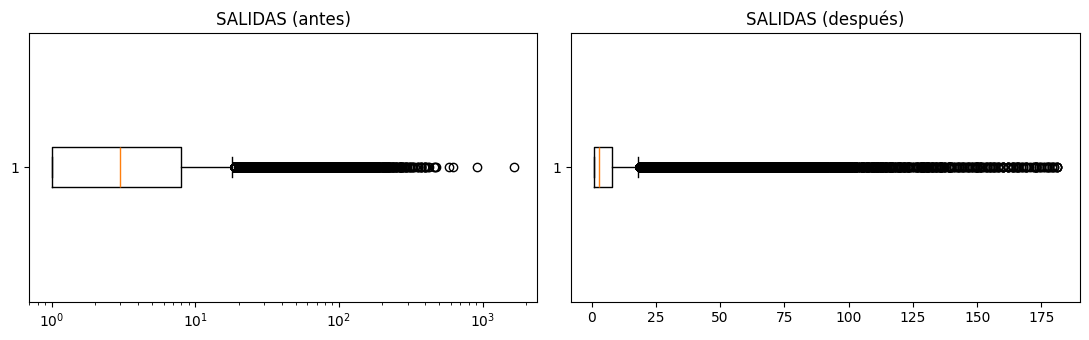

Registros finales: 55050


In [3]:
df['LN_SALIDAS'] = np.log(df.SALIDAS)
q1,q3 = df.LN_SALIDAS.quantile([.25,.75]); iqr=q3-q1
lo,hi = q1-1.5*iqr, q3+1.5*iqr
out = (df.LN_SALIDAS<lo)|(df.LN_SALIDAS>hi)
print(f'Límite inferior: {np.exp(lo):.2f} | Límite superior: {np.exp(hi):.1f} unidades | Outliers: {out.sum()}')
log['Outliers eliminados (IQR sobre ln)'] = int(out.sum())
fig,ax = plt.subplots(1,2,figsize=(11,3.5))
ax[0].boxplot(df.SALIDAS,vert=False); ax[0].set_title('SALIDAS (antes)'); ax[0].set_xscale('log')
ax[1].boxplot(df.SALIDAS[~out],vert=False); ax[1].set_title('SALIDAS (después)')
plt.tight_layout(); plt.savefig('fig_outliers.png',dpi=120); plt.show()
df = df[~out].copy(); log['Registros finales'] = len(df); print('Registros finales:', len(df))

### 1.3 Transformación de SKU y NOMBRE a numérico
Cada categoría se codifica con su **ranking de frecuencia** (1 = la más frecuente en el historial; desempates en orden alfabético). Se inicia en 1 porque los modelos exponencial y potencial requieren x > 0.

In [4]:
def rank_encode(s):
    f = s.value_counts().rename('n').reset_index()
    f.columns = [s.name,'n']
    f = f.sort_values(['n',s.name],ascending=[False,True]).reset_index(drop=True)
    f['codigo'] = np.arange(1,len(f)+1)
    return s.map(dict(zip(f[s.name],f.codigo)))
df['SKU_NUM'] = rank_encode(df.SKU); df['NOMBRE_NUM'] = rank_encode(df.NOMBRE)
print('SKU distintos:',df.SKU.nunique(),'| NOMBRE distintos:',df.NOMBRE.nunique())
df[['SKU','SKU_NUM','NOMBRE','NOMBRE_NUM','SALIDAS']].head()

SKU distintos: 5293 | NOMBRE distintos: 5292


,SKU,SKU_NUM,NOMBRE,NOMBRE_NUM,SALIDAS
0,MFTS502L1.5,265,MFT S50 2L1.5,265,2
1,AKZLCSTANDKIT,782,AKZENT LC STANDARD KIT,774,1
2,LIN23LINF3M2,3521,LINGOFORM 23L INFERIOR 3M2,3415,1
3,LIN23LSUP3M2,5057,LINGOFORM2 23LSUPERIOR 3M2,4833,1
4,PANEXCL39A3,1798,PAN EXCELL L39 A3,1792,1


## 2. Modelos de regresión
Para cada predictora se ajustan tres modelos por mínimos cuadrados no lineales (`curve_fit`) sobre `SALIDAS` en su escala original. Se reportan R², r (con el signo de la pendiente), RMSE y MAE. También se muestra R² de la versión linealizada (ln y) de los modelos exponencial y potencial, que es el que reporta la línea de tendencia de Excel.

In [5]:
modelos = {
 'Lineal simple': (lambda x,a,b: a+b*x,            (5,0),     'y = a + b·x'),
 'Exponencial':   (lambda x,a,b: a*np.exp(b*x),    (5,-1e-4), 'y = a·e^(b·x)'),
 'Potencial':     (lambda x,a,b: a*np.power(x,b),  (5,-.1),   'y = a·x^b'),
}
def ajusta(x,y,xn):
    filas=[]; preds={}
    for nom,(f,p0,eq) in modelos.items():
        p,_ = curve_fit(f,x,y,p0=p0,maxfev=100000); yh=f(x,*p); preds[nom]=(f,p)
        sse=((y-yh)**2).sum(); R2=1-sse/((y-y.mean())**2).sum()
        if nom=='Lineal simple': R2l=R2
        else:
            lx = x if nom=='Exponencial' else np.log(x); R2l=np.corrcoef(lx,np.log(y))[0,1]**2
        filas.append({'Predictora':xn,'Modelo':nom,'Ecuación':eq,'a':p[0],'b':p[1],
                      'R²':R2,'r':np.sign(p[1])*np.sqrt(max(R2,0)),'R² (linealizado)':R2l,
                      'RMSE':np.sqrt(sse/len(y)),'MAE':np.abs(y-yh).mean()})
    return filas,preds
y = df.SALIDAS.values.astype(float)
resultados=[]; ajustes={}
for xn in ['SKU_NUM','NOMBRE_NUM']:
    f,p = ajusta(df[xn].values.astype(float),y,xn); resultados+=f; ajustes[xn]=p
tabla = pd.DataFrame(resultados); tabla.round(5)

,Predictora,Modelo,Ecuación,a,b,R²,r,R² (linealizado),RMSE,MAE
0,SKU_NUM,Lineal simple,y = a + b·x,12.67861,-0.00331,0.04367,-0.20896,0.04367,17.41576,9.79635
1,SKU_NUM,Exponencial,y = a·e^(b·x),35.75932,-0.00534,0.14035,-0.37463,0.07294,16.51197,8.09720
2,SKU_NUM,Potencial,y = a·x^b,92.08294,-0.39050,0.18334,-0.42819,0.20876,16.09375,8.56358
3,NOMBRE_NUM,Lineal simple,y = a + b·x,12.71336,-0.00334,0.04450,-0.21095,0.04450,17.40818,9.79133
4,NOMBRE_NUM,Exponencial,y = a·e^(b·x),35.71983,-0.00532,0.14075,-0.37516,0.07564,16.50813,8.09986
5,NOMBRE_NUM,Potencial,y = a·x^b,92.72190,-0.39189,0.18476,-0.42984,0.21085,16.07975,8.54523


### 2.1 Tabla comparativa de coeficientes de determinación y correlación

In [6]:
comp = tabla[['Predictora','Modelo','R²','r','R² (linealizado)','RMSE','MAE']].copy()
comp['Mejor (R²)'] = comp.groupby('Predictora')['R²'].transform(lambda s: s==s.max()).map({True:'★',False:''})
comp.round(5)

,Predictora,Modelo,R²,r,R² (linealizado),RMSE,MAE,Mejor (R²)
0,SKU_NUM,Lineal simple,0.04367,-0.20896,0.04367,17.41576,9.79635,
1,SKU_NUM,Exponencial,0.14035,-0.37463,0.07294,16.51197,8.09720,
2,SKU_NUM,Potencial,0.18334,-0.42819,0.20876,16.09375,8.56358,★
3,NOMBRE_NUM,Lineal simple,0.04450,-0.21095,0.04450,17.40818,9.79133,
4,NOMBRE_NUM,Exponencial,0.14075,-0.37516,0.07564,16.50813,8.09986,
5,NOMBRE_NUM,Potencial,0.18476,-0.42984,0.21085,16.07975,8.54523,★


### 2.2 Gráficas de los modelos

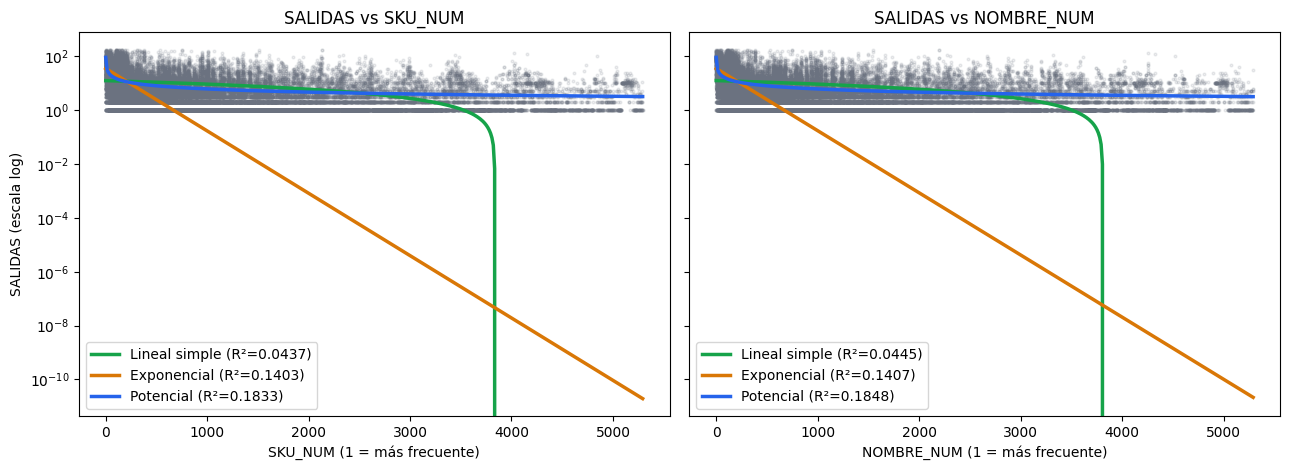

In [7]:
fig,axs = plt.subplots(1,2,figsize=(13,4.8),sharey=True)
cols = {'Lineal simple':'#16a34a','Exponencial':'#d97706','Potencial':'#2563eb'}
for ax,xn in zip(axs,['SKU_NUM','NOMBRE_NUM']):
    x=df[xn].values; ax.scatter(x,y,s=4,alpha=.12,color='#6b7280')
    xs=np.linspace(1,x.max(),400)
    for nom,(f,p) in ajustes[xn].items():
        r=tabla[(tabla.Predictora==xn)&(tabla.Modelo==nom)].iloc[0]
        ax.plot(xs,f(xs,*p),lw=2.5,color=cols[nom],label=f'{nom} (R²={r["R²"]:.4f})')
    ax.set_yscale('log'); ax.set_xlabel(xn+' (1 = más frecuente)'); ax.set_title('SALIDAS vs '+xn); ax.legend()
axs[0].set_ylabel('SALIDAS (escala log)')
plt.tight_layout(); plt.savefig('fig_modelos.png',dpi=120); plt.show()

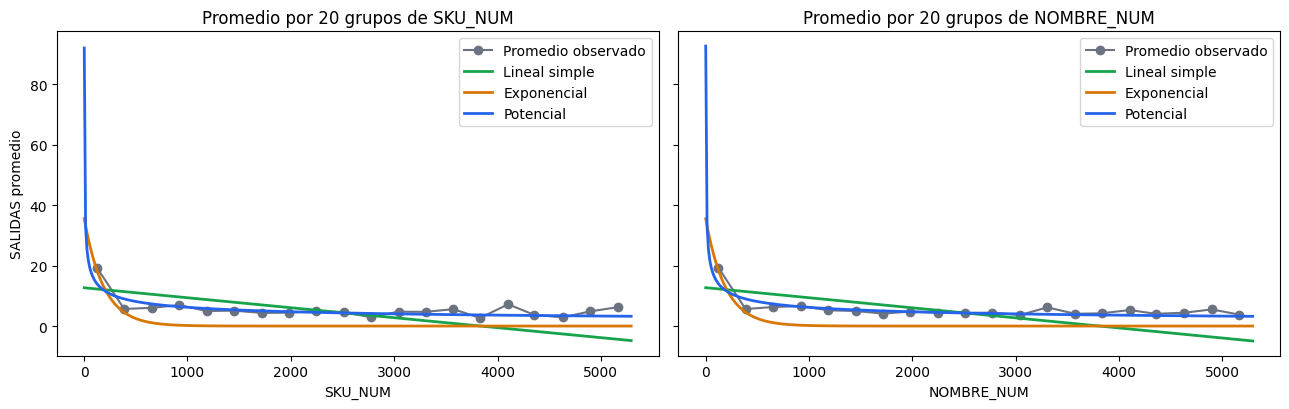

In [8]:
# Promedio de SALIDAS por grupos de código: muestra la tendencia sin el ruido del nivel registro
fig,axs = plt.subplots(1,2,figsize=(13,4.2),sharey=True)
for ax,xn in zip(axs,['SKU_NUM','NOMBRE_NUM']):
    g = df.groupby(pd.cut(df[xn],bins=20),observed=True).agg(x=(xn,'mean'),y=('SALIDAS','mean'))
    ax.plot(g.x,g.y,'o-',color='#6b7280',label='Promedio observado')
    xs=np.linspace(1,df[xn].max(),400)
    for nom,(f,p) in ajustes[xn].items(): ax.plot(xs,f(xs,*p),lw=2,color=cols[nom],label=nom)
    ax.set_title(f'Promedio por 20 grupos de {xn}'); ax.set_xlabel(xn); ax.legend()
axs[0].set_ylabel('SALIDAS promedio')
plt.tight_layout(); plt.savefig('fig_grupos.png',dpi=120); plt.show()

## 3. Exportar resultados

In [9]:
with pd.ExcelWriter('Resultados_Comparacion_Modelos.xlsx') as w:
    tabla.to_excel(w,sheet_name='Coeficientes',index=False)
    comp.to_excel(w,sheet_name='Comparativa',index=False)
    df[['ANO','MES','SKU','SKU_NUM','NOMBRE','NOMBRE_NUM','SALIDAS']].to_excel(w,sheet_name='Datos_limpios',index=False)
pd.Series(log).to_csv('log_preprocesamiento.csv'); tabla.to_csv('tabla_modelos.csv',index=False)
print('Exportado')

Exportado


## 4. Análisis
Ver el reporte (`Reporte_Actividad_8.docx`) para la interpretación de los resultados.